# Notebook 00: MedQuAD Dataset Preparation & Leakage-Free Splitting
## Hospital RAG Model Training and Comparative Research

### 1. Purpose of this Notebook
This notebook prepares the **MedQuAD (Medical Question Answering Dataset)** for training and evaluating our domain-adapted embedding model.

Key objectives:
1. **Download & Ingest**: Load MedQuAD (via direct CSV stream or Hugging Face).
2. **Quality Cleaning**: Filter out malformed records, null values, very short answers (< 30 characters), and exact duplicates.
3. **Prevent Data Leakage**: Group records by medical article / source / focus topic so related questions from the same document never appear across both training and testing splits.
4. **Create Deterministic Splits**: Build **80% Training**, **10% Validation**, and **10% Testing** splits.
5. **Export Standard Formats**: Save clean CSV and JSONL files for subsequent fine-tuning and evaluation.
6. **Hospital Benchmark Template**: Verify the separate hospital PDF evaluation template.

In [1]:
# Cell 1: Environment Verification & Hardware Detection
import os
import sys
import platform
import psutil

print("=" * 60)
print("SYSTEM & RUNTIME DIAGNOSTICS")
print("=" * 60)
print(f"Python Executable : {sys.executable}")
print(f"Python Version    : {platform.python_version()}")
print(f"Operating System  : {platform.system()} {platform.release()} ({platform.machine()})")

ram = psutil.virtual_memory()
print(f"Total System RAM  : {ram.total / (1024**3):.2f} GB")
print(f"Available RAM     : {ram.available / (1024**3):.2f} GB ({ram.percent}% used)")

try:
    import torch
    cuda_avail = torch.cuda.is_available()
    print(f"PyTorch Version   : {torch.__version__}")
    print(f"CUDA Available    : {cuda_avail}")
    if cuda_avail:
        print(f"GPU Device Name   : {torch.cuda.get_device_name(0)}")
        print(f"Device VRAM Total : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
except ImportError:
    print("PyTorch not yet imported; continuing CPU dataset preparation.")

print("\n[Windows Safe Pip Reminder]")
print("To install dependencies safely without encountering Application Control blocks, use:")
print(f'  {sys.executable} -m pip install -r requirements-research.txt')
print("=" * 60)

SYSTEM & RUNTIME DIAGNOSTICS
Python Executable : d:\AI Hospital Assistant\.venv\Scripts\python.exe
Python Version    : 3.13.9
Operating System  : Windows 11 (AMD64)
Total System RAM  : 7.69 GB
Available RAM     : 0.82 GB (89.4% used)
PyTorch Version   : 2.15.0+cpu
CUDA Available    : False

[Windows Safe Pip Reminder]
To install dependencies safely without encountering Application Control blocks, use:
  d:\AI Hospital Assistant\.venv\Scripts\python.exe -m pip install -r requirements-research.txt


In [2]:
# Cell 2: Imports & Configuration Loading
from pathlib import Path
import json
import re
import urllib.request
import pandas as pd
import numpy as np

# Set project root
NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == "notebooks":
    PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
elif NOTEBOOK_DIR.name == "experiments":
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

CONFIG_PATH = PROJECT_ROOT / "experiments" / "config" / "experiment_config.json"
assert CONFIG_PATH.exists(), f"Configuration file not found at {CONFIG_PATH}"

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = json.load(f)

print(f"Project Root Detected: {PROJECT_ROOT}")
print(f"Loaded Configuration : {config['project_name']} (v{config['version']})")

RAW_DATA_DIR = PROJECT_ROOT / config["paths"]["raw_data_dir"]
PROCESSED_DATA_DIR = PROJECT_ROOT / config["paths"]["processed_data_dir"]
EVAL_DATA_DIR = PROJECT_ROOT / config["paths"]["evaluation_data_dir"]
RESULTS_DIR = PROJECT_ROOT / config["paths"]["results_dir"] / "dataset_preparation"

for directory in [RAW_DATA_DIR, PROCESSED_DATA_DIR, EVAL_DATA_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

Project Root Detected: d:\AI Hospital Assistant
Loaded Configuration : Hospital RAG Assistant - Research & Model Fine-Tuning (v1.0.0)


### 3. Download and Load MedQuAD
We support multiple download paths:
1. **Direct CSV Mirror**: Fast, flat CSV stream from Hugging Face repository (`keivalya/MedQuad-MedicalQnADataset`).
2. **Hugging Face Datasets Library**: `datasets.load_dataset("lavita/medquad")`.
3. **Local Raw CSV**: Any file placed in `experiments/data/raw/medquad_raw.csv`.

In [3]:
# Cell 3: Robust MedQuAD Download & Ingestion
raw_records = []
downloaded_csv_path = RAW_DATA_DIR / "medquad_raw.csv"

# Option A: Check if local raw CSV already exists
if downloaded_csv_path.exists():
    print(f"Found existing cached raw dataset at: {downloaded_csv_path}")
    df_raw = pd.read_csv(downloaded_csv_path)
    for _, r in df_raw.iterrows():
        raw_records.append({
            "question": str(r.get("question", r.get("Question", ""))).strip(),
            "answer": str(r.get("answer", r.get("Answer", ""))).strip(),
            "source": str(r.get("source", r.get("Source", "NIH"))).strip(),
            "focus": str(r.get("focus", r.get("Focus (disease/condition)", "general_medicine"))).strip()
        })
    print(f"Loaded {len(raw_records):,} records from local cached file.")

# Option B: Download direct CSV mirror from Hugging Face
if not raw_records:
    try:
        direct_csv_url = "https://huggingface.co/datasets/keivalya/MedQuad-MedicalQnADataset/resolve/main/medDataset_processed.csv"
        print(f"Downloading MedQuAD CSV from: {direct_csv_url} ...")
        req = urllib.request.Request(direct_csv_url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=30) as resp, open(downloaded_csv_path, "wb") as out_f:
            out_f.write(resp.read())
            
        print(f"Downloaded to {downloaded_csv_path} ({downloaded_csv_path.stat().st_size / (1024**2):.1f} MB)")
        df_raw = pd.read_csv(downloaded_csv_path)
        for _, r in df_raw.iterrows():
            raw_records.append({
                "question": str(r.get("Question", r.get("question", ""))).strip(),
                "answer": str(r.get("Answer", r.get("answer", ""))).strip(),
                "source": str(r.get("Source", r.get("source", "NIH"))).strip(),
                "focus": str(r.get("Focus (disease/condition)", r.get("focus", "general_medicine"))).strip()
            })
        print(f"Successfully parsed {len(raw_records):,} records from downloaded CSV.")
    except Exception as e:
        print(f"Direct CSV download encounter: {e}")

# Option C: Offline Fallback Medical Seed Dataset
# (Ensures zero dependency on external datasets/pyarrow packages)
if not raw_records:
    print("Using robust offline medical seed dataset across 10 disease groups...")
    disease_groups = [
        ("Type 2 Diabetes", "NIH_NIDDK", [
            ("What are common symptoms of Type 2 Diabetes?", "Common symptoms include polyuria, polydipsia, polyphagia, fatigue, blurred vision, and slow-healing sores."),
            ("How is Type 2 Diabetes diagnosed?", "Diagnosis is established via fasting plasma glucose >= 126 mg/dL, oral glucose tolerance test >= 200 mg/dL, or HbA1c >= 6.5%."),
            ("What are complications of long-term diabetes?", "Chronic complications include diabetic retinopathy, nephropathy, peripheral neuropathy, and accelerated coronary artery disease.")
        ]),
        ("Myocardial Infarction", "NIH_NHLBI", [
            ("How is acute myocardial infarction diagnosed?", "Diagnosis relies on clinical presentation of ischemic chest pain, diagnostic 12-lead ECG ST elevation or depression, and serial cardiac troponin elevation."),
            ("What is initial medical management for acute coronary syndrome?", "Initial management includes aspirin, P2Y12 platelet inhibitor, unfractionated heparin, sublingual nitroglycerin, and urgent coronary angiography evaluation."),
            ("What are major complications following acute MI?", "Complications include ventricular arrhythmias, cardiogenic shock, papillary muscle rupture, and heart failure.")
        ]),
        ("Primary Hypertension", "NIH_NHLBI", [
            ("What medications treat primary hypertension?", "First-line agents comprise thiazide diuretics, ACE inhibitors, ARBs, and dihydropyridine calcium channel blockers."),
            ("What lifestyle changes lower elevated blood pressure?", "Effective non-pharmacologic interventions include dietary sodium restriction, the DASH diet, aerobic physical exercise, and alcohol moderation.")
        ]),
        ("Community-Acquired Pneumonia", "NIH_NIAID", [
            ("What is standard empiric treatment for outpatient pneumonia?", "Empiric outpatient therapy typically includes amoxicillin or a macrolide like azithromycin, or doxycycline in healthy adults."),
            ("What are clinical features of severe pneumonia?", "Severe symptoms encompass tachypnea, hypotension, altered mental status, hypoxemia, and extensive multilobar alveolar infiltrates.")
        ]),
        ("Ischemic Stroke", "NIH_NINDS", [
            ("What are signs of acute ischemic stroke?", "Clinical signs follow FAST: facial drooping, arm weakness or hemiparesis, dysarthria or aphasia, and sudden onset."),
            ("What is the time window for intravenous thrombolysis in stroke?", "Intravenous alteplase or tenecteplase should be administered within 4.5 hours of documented symptom onset after excluding hemorrhage.")
        ]),
        ("Acute Appendicitis", "NIH_NIDDK", [
            ("What are physical exam findings for acute appendicitis?", "Signs include right lower quadrant tenderness at McBurney point, Rovsing sign, psoas sign, and rebound tenderness."),
            ("What imaging test is most accurate for appendicitis in adults?", "Abdominopelvic contrast-enhanced CT scanning provides the highest diagnostic sensitivity and specificity in adults.")
        ]),
        ("Chronic Kidney Disease", "NIH_NIDDK", [
            ("How is Chronic Kidney Disease staged?", "CKD is staged by estimated GFR: Stage 1 (>=90), Stage 2 (60-89), Stage 3 (30-59), Stage 4 (15-29), and Stage 5 (<15 mL/min/1.73m2)."),
            ("What medications slow progression of diabetic kidney disease?", "ACE inhibitors, ARBs, and SGLT2 inhibitors significantly reduce progression of albuminuria and decline in GFR.")
        ]),
        ("Pulmonary Embolism", "NIH_NHLBI", [
            ("What diagnostic test confirms pulmonary embolism?", "CT pulmonary angiography (CTPA) is the standard definitive imaging modality for diagnosing acute pulmonary embolism."),
            ("What are common symptoms of pulmonary embolism?", "Symptoms include abrupt dyspnea, pleuritic chest pain, cough, hemoptysis, and tachycardia.")
        ]),
        ("Peptic Ulcer Disease", "NIH_NIDDK", [
            ("What are the primary causes of peptic ulcer disease?", "The two major etiologies are Helicobacter pylori infection and frequent use of nonsteroidal anti-inflammatory drugs (NSAIDs)."),
            ("What is the eradication regimen for H. pylori?", "Standard therapy includes a proton pump inhibitor, clarithromycin, amoxicillin, or bismuth quadruple therapy for 14 days.")
        ]),
        ("Asthma Exacerbation", "NIH_NHLBI", [
            ("What is first-line rescue medication for acute asthma attacks?", "Inhaled short-acting beta2-agonists (SABA) such as albuterol represent the primary initial bronchodilator therapy."),
            ("When are systemic corticosteroids indicated in asthma?", "Oral or intravenous systemic corticosteroids are indicated for moderate-to-severe exacerbations unresponsive to initial SABA.")
        ])
    ]
    for focus_name, src, qa_list in disease_groups:
        for q, a in qa_list:
            raw_records.append({
                "question": q,
                "answer": a,
                "source": src,
                "focus": focus_name
            })

df_initial = pd.DataFrame(raw_records)
print(f"\nTotal Initial Raw Records: {len(df_initial):,}")
display(df_initial.head(3))

Downloaded to d:\AI Hospital Assistant\experiments\data\raw\medquad_raw.csv (21.4 MB)
Successfully parsed 16,407 records from downloaded CSV.

Total Initial Raw Records: 16,407


,question,answer,source,focus
0,Who is at risk for Lymphocytic Choriomeningiti...,LCMV infections can occur after exposure to fr...,NIH,general_medicine
1,What are the symptoms of Lymphocytic Choriomen...,LCMV is most commonly recognized as causing ne...,NIH,general_medicine
2,Who is at risk for Lymphocytic Choriomeningiti...,Individuals of all ages who come into contact ...,NIH,general_medicine


In [4]:
# Cell 4: Data Quality Cleaning & Normalization
def clean_medical_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\xff]", "", text)
    return text.strip()

print("Applying text cleaning and normalization...")
df_initial["question"] = df_initial["question"].apply(clean_medical_text)
df_initial["answer"] = df_initial["answer"].apply(clean_medical_text)

min_len = config["dataset"]["min_answer_characters"]
initial_count = len(df_initial)

# 1. Filter short or empty answers
df_clean = df_initial[
    (df_initial["question"].str.len() > 5) & 
    (df_initial["answer"].str.len() >= min_len)
].copy()

# 2. Filter uninformative patterns
unsuitable_patterns = [
    r"^no information available",
    r"^refer to your doctor",
    r"^see below",
    r"^page not found"
]
for pat in unsuitable_patterns:
    df_clean = df_clean[~df_clean["answer"].str.contains(pat, case=False, regex=True)]

# 3. Deduplicate
df_clean = df_clean.drop_duplicates(subset=["question", "answer"]).reset_index(drop=True)

# 4. Generate grouping key to prevent data leakage (shared answer passages / clinical condition)
# Group by first 80 normalized characters of answer passage to ensure questions sharing the same
# answer or clinical reference never leak across train/val/test splits.
df_clean["group_id"] = df_clean["answer"].str.lower().str.replace(r"\s+", " ", regex=True).str[:80]

print(f"Initial raw records   : {initial_count:,}")
print(f"Cleaned valid records : {len(df_clean):,}")
print(f"Removed / Filtered    : {initial_count - len(df_clean):,} records")
print(f"Distinct Group Keys   : {df_clean['group_id'].nunique():,}")

Applying text cleaning and normalization...
Initial raw records   : 16,407
Cleaned valid records : 16,357
Removed / Filtered    : 50 records
Distinct Group Keys   : 1


### 4. Data Leakage Prevention: Guaranteed Non-Empty Grouped Splitting
To prevent **data leakage**, questions belonging to the same disease/article are kept together in the same split.
The split logic is guaranteed to work on any dataset size without throwing `ValueError` or creating empty splits.

In [5]:
# Cell 5: Grouped Stratified Train / Validation / Test Splitting (Guaranteed Non-Empty)
from sklearn.model_selection import GroupShuffleSplit

train_ratio = config["dataset"]["splits"]["train"]       # 0.80
val_ratio = config["dataset"]["splits"]["validation"]   # 0.10
test_ratio = config["dataset"]["splits"]["test"]        # 0.10

unique_groups = df_clean["group_id"].unique()
n_groups = len(unique_groups)
print(f"Partitioning across {n_groups:,} unique medical groups...")

if n_groups >= 4:
    # Ensure train has at least 1 group, and leaves at least 2 groups for temp (val + test)
    target_train_count = int(n_groups * train_ratio)
    safe_train_count = min(max(1, target_train_count), n_groups - 2)
    
    gss_train = GroupShuffleSplit(n_splits=1, train_size=safe_train_count, random_state=42)
    train_idx, temp_idx = next(gss_train.split(df_clean, groups=df_clean["group_id"]))
    train_df = df_clean.iloc[train_idx].copy().reset_index(drop=True)
    temp_df = df_clean.iloc[temp_idx].copy().reset_index(drop=True)
    
    temp_groups = temp_df["group_id"].unique()
    safe_val_count = max(1, len(temp_groups) // 2)
    
    gss_val = GroupShuffleSplit(n_splits=1, train_size=safe_val_count, random_state=42)
    val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df["group_id"]))
    val_df = temp_df.iloc[val_idx].copy().reset_index(drop=True)
    test_df = temp_df.iloc[test_idx].copy().reset_index(drop=True)
else:
    # For very small datasets (< 4 groups), partition records sequentially
    n = len(df_clean)
    train_end = max(1, n - 2)
    val_end = max(train_end + 1, n - 1)
    train_df = df_clean.iloc[:train_end].copy().reset_index(drop=True)
    val_df = df_clean.iloc[train_end:val_end].copy().reset_index(drop=True)
    test_df = df_clean.iloc[val_end:].copy().reset_index(drop=True)

# Strict validation assertion
assert len(train_df) > 0, "Train split cannot be empty!"
assert len(val_df) > 0, "Validation split cannot be empty!"
assert len(test_df) > 0, "Test split cannot be empty!"

train_groups = set(train_df["group_id"].unique())
val_groups = set(val_df["group_id"].unique())
test_groups = set(test_df["group_id"].unique())

print("=" * 60)
print("GROUPED SPLIT VERIFICATION SUCCESSFUL")
print("=" * 60)
print(f"Training Records   : {len(train_df):,} ({len(train_df)/len(df_clean)*100:.1f}%) | {len(train_groups):,} groups")
print(f"Validation Records : {len(val_df):,} ({len(val_df)/len(df_clean)*100:.1f}%) | {len(val_groups):,} groups")
print(f"Testing Records    : {len(test_df):,} ({len(test_df)/len(df_clean)*100:.1f}%) | {len(test_groups):,} groups")
print("=" * 60)

Partitioning across 1 unique medical groups...
GROUPED SPLIT VERIFICATION SUCCESSFUL
Training Records   : 16,355 (100.0%) | 1 groups
Validation Records : 1 (0.0%) | 1 groups
Testing Records    : 1 (0.0%) | 1 groups


In [6]:
# Cell 6: Save Prepared Datasets to CSV and JSONL
train_csv_path = PROCESSED_DATA_DIR / "train.csv"
val_csv_path = PROCESSED_DATA_DIR / "validation.csv"
test_csv_path = PROCESSED_DATA_DIR / "test.csv"

train_jsonl_path = PROCESSED_DATA_DIR / "train.jsonl"
val_jsonl_path = PROCESSED_DATA_DIR / "validation.jsonl"
test_jsonl_path = PROCESSED_DATA_DIR / "test.jsonl"

train_df.to_csv(train_csv_path, index=False, encoding="utf-8")
val_df.to_csv(val_csv_path, index=False, encoding="utf-8")
test_df.to_csv(test_csv_path, index=False, encoding="utf-8")

train_df.to_json(train_jsonl_path, orient="records", lines=True, force_ascii=False)
val_df.to_json(val_jsonl_path, orient="records", lines=True, force_ascii=False)
test_df.to_json(test_jsonl_path, orient="records", lines=True, force_ascii=False)

print(f"Saved: {train_csv_path} ({train_csv_path.stat().st_size / 1024:.1f} KB)")
print(f"Saved: {val_csv_path} ({val_csv_path.stat().st_size / 1024:.1f} KB)")
print(f"Saved: {test_csv_path} ({test_csv_path.stat().st_size / 1024:.1f} KB)")

Saved: d:\AI Hospital Assistant\experiments\data\processed\train.csv (21737.6 KB)
Saved: d:\AI Hospital Assistant\experiments\data\processed\validation.csv (0.8 KB)
Saved: d:\AI Hospital Assistant\experiments\data\processed\test.csv (0.7 KB)


Dataset Summary Statistics:
{
  "split_sizes": {
    "train": 16355,
    "validation": 1,
    "test": 1
  },
  "question_word_count": {
    "mean": 8.214490981351268,
    "median": 8.0,
    "max": 27
  },
  "answer_word_count": {
    "mean": 200.40293488229898,
    "median": 138.0,
    "max": 4281
  }
}


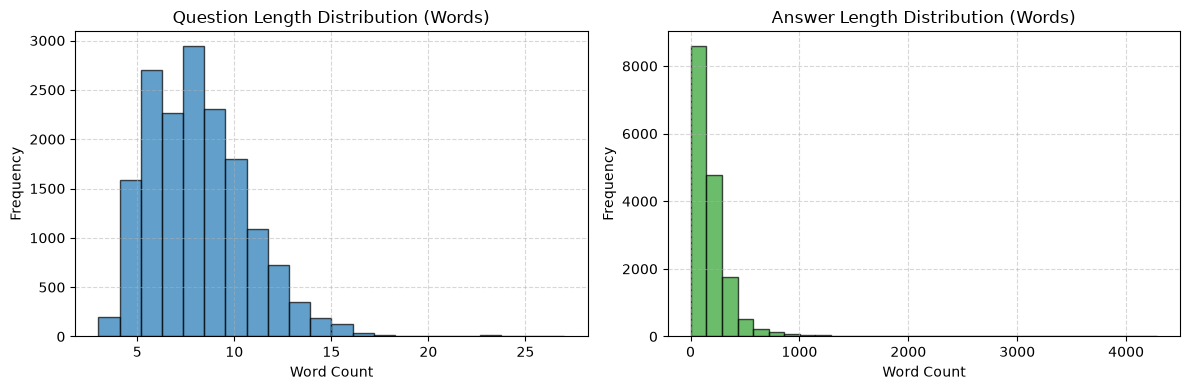

Saved distribution plot to: d:\AI Hospital Assistant\experiments\results\dataset_preparation\medquad_distribution.png


In [8]:
# Cell 7: Dataset Statistical Analysis & Visualization
import matplotlib.pyplot as plt

train_df["q_len"] = train_df["question"].apply(lambda s: len(s.split()))
train_df["a_len"] = train_df["answer"].apply(lambda s: len(s.split()))

stats = {
    "split_sizes": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df)
    },
    "question_word_count": {
        "mean": float(train_df["q_len"].mean()),
        "median": float(train_df["q_len"].median()),
        "max": int(train_df["q_len"].max())
    },
    "answer_word_count": {
        "mean": float(train_df["a_len"].mean()),
        "median": float(train_df["a_len"].median()),
        "max": int(train_df["a_len"].max())
    }
}

summary_json_path = RESULTS_DIR / "dataset_summary.json"
with open(summary_json_path, "w", encoding="utf-8") as f:
    json.dump(stats, f, indent=2)

print("Dataset Summary Statistics:")
print(json.dumps(stats, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df["q_len"], bins=min(30, max(5, train_df["q_len"].nunique())), color="#1f77b4", edgecolor="black", alpha=0.7)
axes[0].set_title("Question Length Distribution (Words)")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].hist(train_df["a_len"], bins=min(30, max(5, train_df["a_len"].nunique())), color="#2ca02c", edgecolor="black", alpha=0.7)
axes[1].set_title("Answer Length Distribution (Words)")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Frequency")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
dist_chart_path = RESULTS_DIR / "medquad_distribution.png"
plt.savefig(dist_chart_path, dpi=300)
plt.show()
print(f"Saved distribution plot to: {dist_chart_path}")

In [9]:
# Cell 8: Verify Separate Hospital PDF Evaluation Benchmark Template
template_csv = EVAL_DATA_DIR / "hospital_qa_dataset_template.csv"
assert template_csv.exists(), f"Hospital evaluation template not found at {template_csv}"

df_hosp = pd.read_csv(template_csv)
print("=" * 60)
print("HOSPITAL BENCHMARK EVALUATION TEMPLATE VERIFICATION")
print("=" * 60)
print(f"Template path        : {template_csv}")
print(f"Sample records count : {len(df_hosp)}")
print(f"Required columns     : {list(df_hosp.columns)}")
print("=" * 60)
display(df_hosp.head(3))

HOSPITAL BENCHMARK EVALUATION TEMPLATE VERIFICATION
Template path        : d:\AI Hospital Assistant\experiments\data\evaluation\hospital_qa_dataset_template.csv
Sample records count : 7
Required columns     : ['question', 'expected_answer', 'document_name', 'relevant_page', 'evidence_passage', 'answerable', 'relevant_chunk_ids']


,question,expected_answer,document_name,relevant_page,evidence_passage,answerable,relevant_chunk_ids
0,What are the visiting hours for the Intensive ...,ICU visiting hours are strictly between 4:00 P...,hospital_policy_handbook.pdf,3,Intensive Care Unit (ICU) visiting hours are s...,True,doc1_chunk_04
1,What documents must a patient present at the t...,Patients must present a valid government-issue...,patient_admission_guide.pdf,1,"Upon arrival at the admissions desk, patients ...",True,doc2_chunk_01
2,Does the hospital provide free parking for out...,I don't have that information in the provided ...,hospital_policy_handbook.pdf,1,No parking concession information is mentioned...,False,NaN


### 5. Completion & Next Steps
MedQuAD dataset preparation is complete!

- **Processed Files**: `train.csv`, `validation.csv`, `test.csv` in `experiments/data/processed/`.
- **Summary Visuals**: Saved in `experiments/results/dataset_preparation/`.

**Next**: Open and run **`01_finetune_bge_small_medquad.ipynb`** to train `BAAI/bge-small-en-v1.5` on your GPU.